### Helper Functions

In [645]:

from pathlib import Path
import sys
import os
# Parent directory
parent_dir = os.path.dirname(os.getcwd())
if parent_dir not in sys.path: sys.path.insert(0, parent_dir)

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from tqdm import trange

from config import C, SYSTEM, ARRAY, SIM
from signal_model.propagation import propagation_delays, received_signal
from signal_model.noise import add_awgn
from localization.pipeline import localize
from signal_model.gaussian_source import gaussian_pulse



N_MC = 1 # 2000
R_MIN, R_MAX = 50.0, 400.0
THETA_MIN, THETA_MAX = -60.0, 60.0
CLOCK_OFFSET = 10e-9


def build_time_axis(R, theta, clock_offset, antenna_x):
    delays = propagation_delays(R, theta, clock_offset=clock_offset, antenna_x=antenna_x)
    margin = 8.0 * SYSTEM.gaussian_sigma
    n0 = int(np.floor((delays.min() - margin) / SYSTEM.dt))
    n1 = int(np.ceil((delays.max() + margin) / SYSTEM.dt))
    return np.arange(n0, n1 + 1) * SYSTEM.dt


def polar_to_xy(R, theta_deg):
    t = np.deg2rad(theta_deg)
    return R * np.sin(t), R * np.cos(t)

def draw_user_region(ax, rmin=R_MIN, rmax=R_MAX, thmin=THETA_MIN, thmax=THETA_MAX):
    th = np.deg2rad(np.linspace(thmin, thmax, 600))
    for r, lw, ls, a in [(rmin, 1.5, "--", 0.9), (rmax, 2.0, "-", 1.0)]:
        ax.plot(r * np.sin(th), r * np.cos(th), color="k", lw=lw, ls=ls, alpha=a)

    for th_deg, lw, ls, a in [(thmin, 1.5, "--", 0.9), (thmax, 1.5, "--", 0.9), (0.0, 1.0, ":", 0.7)]:
        t = np.deg2rad(th_deg)
        rr = np.linspace(rmin, rmax, 300)
        ax.plot(rr * np.sin(t), rr * np.cos(t), color="k", lw=lw, ls=ls, alpha=a)

    for r in [100, 200, 300]:
        ax.plot(r * np.sin(th), r * np.cos(th), color="gray", lw=0.8, ls=":", alpha=0.5)

    ax.text(rmax * np.sin(np.deg2rad(thmin)) - 18, rmax * np.cos(np.deg2rad(thmin)) - 5, f"{thmin:.0f}°", fontsize=10)
    ax.text(rmax * np.sin(np.deg2rad(thmax)) + 4, rmax * np.cos(np.deg2rad(thmax)) - 5, f"{thmax:.0f}°", fontsize=10)
    ax.text(0, rmax + 8, "0°", ha="center", fontsize=10)
    ax.text(8, rmin + 2, f"R={int(rmin)} m", fontsize=9)
    ax.text(8, rmax - 8, f"R={int(rmax)} m", fontsize=9)


def snr_db_at_range(R):
    return SIM.reference_snr_db + 20.0 * np.log10(SIM.reference_range / R)

### Actual Experiment Steps

In [646]:
antenna_x = ARRAY.positions(SYSTEM)
rng_pos = np.random.default_rng(SIM.rng_seed)
rng_noise = np.random.default_rng(SIM.rng_seed + 1)

errors = np.zeros(N_MC)
snrs = np.zeros(N_MC)
x_true_all = np.zeros(N_MC)
y_true_all = np.zeros(N_MC)

for i in trange(N_MC, desc="Monte Carlo"):
    R_true = rng_pos.uniform(R_MIN, R_MAX)
    theta_true = rng_pos.uniform(THETA_MIN, THETA_MAX)
    tau_true = R_true / C + CLOCK_OFFSET
    x_true, y_true = polar_to_xy(R_true, theta_true)

    time_axis = build_time_axis(R_true, theta_true, CLOCK_OFFSET, antenna_x)
    delay_axis = propagation_delays(R_true, theta_true, CLOCK_OFFSET, antenna_x)
    clean_rx, _ = received_signal(time_axis, R_true, theta_true, clock_offset=CLOCK_OFFSET, antenna_x=antenna_x)
    noisy_rx, _ = add_awgn(clean_rx, rng=rng_noise)

    result = localize(noisy_rx, time_axis, antenna_x, theta_true, tau_true)

    x_true_all[i], y_true_all[i] = x_true, y_true
    errors[i] = np.hypot(result.x - x_true, result.y - y_true)
    snrs[i] = snr_db_at_range(R_true)
    

Monte Carlo: 100%|██████████| 1/1 [00:00<00:00,  1.67it/s]


In [679]:
print((time_axis[-1] + time_axis[0])/tau_true/2)
print(CLOCK_OFFSET)
print(C * (tau_true - CLOCK_OFFSET)) 
print(R_true)

1.0000121887226983
1e-08
272.93659056250897
272.93659056250897


In [647]:
print("\nResult Parameters:")
result_key = vars(result).keys()

for key in result_key:
    print(f"{key}: {getattr(result, key)}")


print("\nSystem Parameters:")
system_key = vars(SYSTEM).keys()

for key in system_key:
    if getattr(SYSTEM, key) > 1e9:
        print(f"{key}: {getattr(SYSTEM, key) / 1e9} GHz")
    else:
        print(f"{key}: {getattr(SYSTEM, key)}")



Result Parameters:
R: 272.0
theta: -27.63
tau: 9.204179687500001e-07
x: -126.14271638241581
y: 240.98135841526292
prt_R: 282.1172449591847
prt_theta: -27.60570896084267
prt_tau: 9.204218750000001e-07
roi: ROI(R_min=252.45466238305772, R_max=311.77982753531165, theta_min=-28.055487357759908, theta_max=-27.157769389828125, tau_min=9.203906250000001e-07, tau_max=9.20453125e-07, W_R=29.66258257612698, W_theta=0.44977839691723887, W_tau=3.125e-11)
prt_peak: 3.510665603742271e-05
hrt_peak: 3.5126071187676104e-05

System Parameters:
fc: 24.0 GHz
bandwidth: 8.0 GHz
oversamp: 8


In [648]:
print(SYSTEM.fs/1e9, "GHz")
print(clean_rx.shape)
print(clean_rx.dtype)
print(clean_rx.device)
print(type(clean_rx))
print(f"Delay span across array: {(delay_axis.max() - delay_axis.min()) / SYSTEM.dt:.3f} Samples")

# Number of Slepian Beams
print(f"Number of Slepian Beams: {2 * (delay_axis.max() - delay_axis.min()) * SYSTEM.bandwidth + 1:.3f} Samples") 

64.0 GHz
(513, 348)
complex128
cpu
<class 'numpy.ndarray'>
Delay span across array: 316.543 Samples
Number of Slepian Beams: 80.136 Samples


In [649]:
# plt.Figure
# # plt.plot(20*np.log10(np.abs(clean_rx[0, :])))
# for i in range(513):
#     plt.plot(time_axis, np.abs(clean_rx[i, :]))
# plt.grid()
# plt.show()

# # Now we would like to see the svd of the covariance matrix 
# # Please overlay the clean and the noisy svds in the same plot

# cov_matrix = np.cov(noisy_rx)
# norm_factor = np.trace(cov_matrix)
# cov_matrix = cov_matrix / norm_factor * noisy_rx.shape[0]  # Normalize the covariance matrix
# # Compute SVD Here 
# U, s_noisy, Vh = np.linalg.svd(cov_matrix)

# # Compute the covariance matrix of the clean signal
# cov_matrix_clean = np.cov(clean_rx)
# cov_matrix_clean = cov_matrix_clean / norm_factor * clean_rx.shape[0]  # Normalize the covariance matrix
# # Compute SVD Here 
# U, s_clean, Vh = np.linalg.svd(cov_matrix_clean)

# plt.Figure
# # Please plot the singular values in dB scale
# plt.plot(20*np.log10(s_noisy),'-d')
# plt.plot(20*np.log10(s_clean),'-o')
# plt.grid()
# # Please limit the y-axis to -100 dB to 0 dB
# plt.ylim(-30, 30)
# # Please limit the x-axis to 0 to 10
# # plt.xlim(0, 300)
# plt.show()


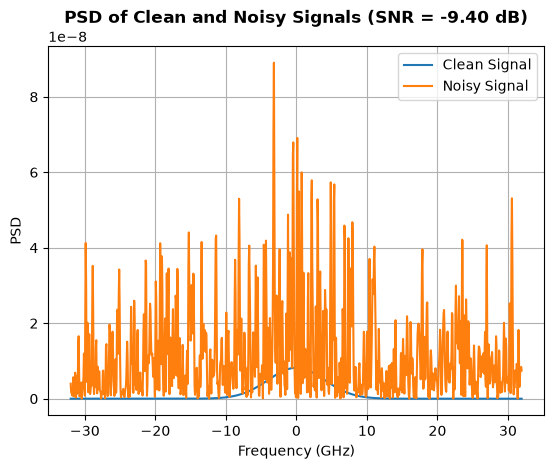

In [650]:
# Please help me visualize the PSD of clean_rx[1, :] and noisy_rx[1, :] using matplotlib. 
# Use the same plot for both signals and use different colors for each signal. 
# Use a logarithmic scale for the y-axis and label the axes appropriately.

# Please compute the SNR here and use it as the title of the plot
idx_pulse_start = np.abs(time_axis - delay_axis.min()).argmin()-10
idx_pulse_end = np.abs(time_axis - delay_axis.max()).argmin()+10

snr = 10 * np.log10(np.mean(np.abs(clean_rx[:, idx_pulse_start:idx_pulse_end])**2) /  \
                    np.mean(np.abs(noisy_rx[:, idx_pulse_start:idx_pulse_end] -  \
                                   clean_rx[:, idx_pulse_start:idx_pulse_end])**2))

psd_clean_rx = np.fft.fftshift(np.abs(np.fft.fft(clean_rx[1, idx_pulse_start:idx_pulse_end], n = 1024))**2)
psd_noisy_rx = np.fft.fftshift(np.abs(np.fft.fft(noisy_rx[1, idx_pulse_start:idx_pulse_end], n = 1024))**2)
freq_axis    = np.fft.fftshift(np.fft.fftfreq(1024, d=SYSTEM.dt))

plt.figure()
plt.plot(freq_axis/1e9, psd_clean_rx, label='Clean Signal')
plt.plot(freq_axis/1e9, psd_noisy_rx, label='Noisy Signal')
plt.xlabel('Frequency (GHz)')
plt.ylabel('PSD')

plt.legend()
plt.grid()
plt.title(f'PSD of Clean and Noisy Signals (SNR = {snr:.2f} dB)', fontsize=12, fontweight='bold')
plt.show()


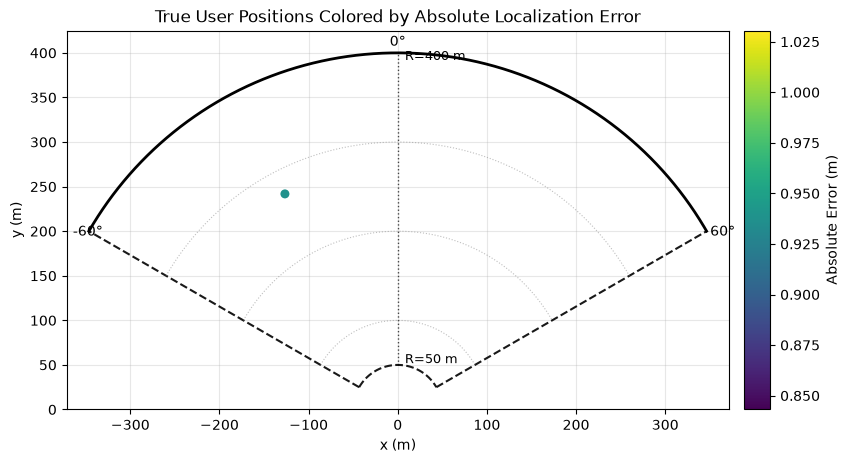

In [651]:
# Can we visualize the received energy of clean and noisy signals as a 
# function of the position?

fig, ax = plt.subplots(figsize=(8.6, 8.2))
sc = ax.scatter(
x_true_all, y_true_all, c=errors, s=42,
cmap="viridis", edgecolors="none"
)
draw_user_region(ax)

xmax = R_MAX * np.sin(np.deg2rad(max(abs(THETA_MIN), abs(THETA_MAX))))
ax.set_xlim(-xmax - 25, xmax + 25)
ax.set_ylim(0, R_MAX + 25)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("True User Positions Colored by Absolute Localization Error")
ax.grid(True, alpha=0.3)

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.15)
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("Absolute Error (m)")

plt.tight_layout()
plt.show()

In [652]:
# let's visualize the SNR as a function of the position
# THE MOST IMPORTANT THING IS TO compute the beamforming weights and    
# the SNR at each position in the user region.

# To do this, we need to compute the combining weights for each position 

antenna_x = ARRAY.positions(SYSTEM)

# Sample the range and angle space to create a grid of positions
range_axis  = np.linspace(R_MIN, R_MAX, 30)
angle_axis  = np.linspace(theta_true - 2, theta_true + 2, 30)

# Please create a 3D tensor with shape (len(range_axis), len(angle_axis), len(antenna_x)) 
# to store the propagation delay for each position
prop_delays = np.zeros((len(range_axis), len(angle_axis), len(antenna_x)), dtype=np.float64)

for r_idx, r in enumerate(range_axis):
    for th_idx, th in enumerate(angle_axis):
        delays = propagation_delays(r, th, antenna_x=antenna_x)
        prop_delays[r_idx, th_idx, :] = delays - np.mean(delays)


# Now let's try to combine the received signals using only the phaseshifts 
# due to the propagation delays & the signal carrier frequency.

weights_ps = np.exp(-1j * 2 * np.pi * SYSTEM.fc * prop_delays)/np.sqrt(len(antenna_x))

# Now let's compute the SNR at each position in 
# the user region using the combining weights and the received signals.

combined_samples = np.einsum('kl,ijk->ijl', clean_rx, weights_ps.conj())
signal_power = np.mean(np.abs(combined_samples)**2, axis = 2)

combined_noise  = np.einsum('kl,ijk->ijl', noisy_rx - clean_rx, weights_ps.conj())
noise_power = np.mean(np.abs(combined_noise)**2, axis = 2)

snr_map = 10*np.log10(signal_power / noise_power)


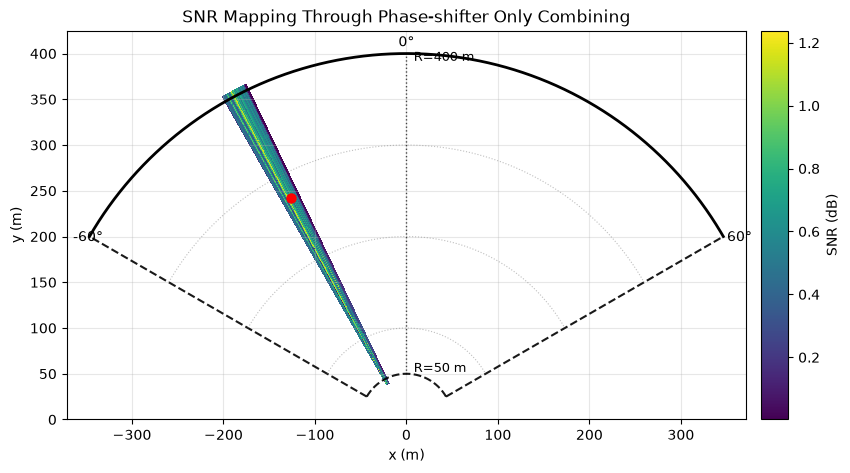

In [653]:
fig, ax = plt.subplots(figsize=(8.6, 8.2))
snr_map_range, snr_map_angle = np.meshgrid(range_axis, angle_axis, indexing='ij')

sc = ax.pcolor(
snr_map_range * np.sin(snr_map_angle/180*np.pi), snr_map_range * np.cos(snr_map_angle/180*np.pi), snr_map,
cmap="viridis", edgecolors="none")
ax.scatter(
x_true_all, y_true_all, c='r', s=42,
)

draw_user_region(ax)


xmax = R_MAX * np.sin(np.deg2rad(max(abs(THETA_MIN), abs(THETA_MAX))))
ax.set_xlim(-xmax - 25, xmax + 25)
ax.set_ylim(0, R_MAX + 25)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("SNR Mapping Through Phase-shifter Only Combining")
ax.grid(True, alpha=0.3)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.15)
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("SNR (dB)")

plt.tight_layout()
# plt.savefig('../figures/SNRMap_PhaseOnly_261011.png')
plt.show()

### First Version of Slepian Beam Generation (DELETED)

### Second Version of Slepian Beam Generation

In [654]:
# Now it's time to do slepian beamforming and see how the SNR map looks like.
# The so-called Slepian beamforming is a technique that uses the Slepian sequences 

def get_SlaBeam(delay_axis, K, bandwidth, dt):
    from scipy.signal import windows
    from scipy.sparse.linalg import eigsh

    delay_axis_centered = delay_axis - np.mean(delay_axis)

    # Default Slepian Sequence Length
    M         = 257
    # Define temporal auto-correlation length
    k         = 51
    # Compute Maximum Delay Axis & Oversampling Ratio 
    temporal_axis   = np.linspace(-k-1, k+1, M)
    os_r            = M / (2 * k + 3)
    
    # Compute the time-bandwidth product
    NW = bandwidth * dt * (2 * k + 3) / os_r

    n_beams =  np.int32(NW * os_r + 1) 
    # print(np.int32(NW * os_r + 1))

    # Compute the Slepian sequences using the DPSS (Discrete Prolate Spheroidal Sequences)
    slepian_sequences, slepian_concentration = windows.dpss(M, NW=NW/2, 
                                                Kmax=n_beams, 
                                                sym=False, 
                                                return_ratios=True)
    
    slepian_sequences = slepian_sequences[slepian_concentration >= 1e-8, :] 


    # Now we need to create integer and fractional delay 
    st_delay        = np.arange(-k, k + 1)

    # Compute Interger Delay 
    frac_delay  = (delay_axis_centered / dt) % 1
    int_delay   = np.int32(delay_axis_centered / dt - frac_delay)

    # Create Entry Mask in Slepian Interpolation 
    int_delay_idx = int_delay + np.int32((K-1)/2)
    entry_idx_y   = np.int32(int_delay_idx[:, None] + st_delay[None, :])
    entry_idx_x   = np.int32(np.arange(0, len(delay_axis))[:, None] * np.ones((1, 2*k + 1)))


    # Create Slepian Interpolation
    slepian_delay     = frac_delay[:, None] + st_delay[None, :] 
    slepian_seq_interpol    = np.zeros((len(delay_axis), K, slepian_sequences.shape[0]), \
                                                    dtype = np.complex128)

    # Now let's try to combine the received signals using only the phaseshifts 
    # due to the propagation delays & the signal carrier frequency.
    weights_ps = np.exp(-1j * 2 * np.pi * SYSTEM.fc * delay_axis_centered)/np.sqrt(len(delay_axis))

    for seq_idx in range(slepian_sequences.shape[0]):
        slepian_beam = np.interp(slepian_delay.reshape(-1), 
                                    temporal_axis, 
                                    slepian_sequences[seq_idx,:], left=0, right=0)
        slepian_beam = slepian_beam.reshape(len(delay_axis), 2*k+1) * weights_ps[:, None] * np.sqrt(slepian_concentration[seq_idx])

        slepian_seq_interpol[entry_idx_x.reshape(-1),
                            entry_idx_y.reshape(-1),
                            seq_idx] = slepian_beam.reshape(-1)


    # Compute the dominant eigenvector of the covariance matrix of the Slepian beams
    slepian_seq_cov       = np.einsum('ijk, ijl', slepian_seq_interpol.conj(), slepian_seq_interpol)
    eig_value, eig_vec    = eigsh(slepian_seq_cov, k=1, which = 'LM')

    # Directly Select the fist Slepain Beam
    slepian_weights = np.sum(slepian_seq_interpol * eig_vec[None, None, :, 0], axis = 2)

    return slepian_weights

def get_FracLPFBeam(delay_axis, K, bandwidth, dt):

    delay_axis_centered = delay_axis - np.mean(delay_axis)

    t                   = np.arange(-np.int32((K-1)/2), np.int32((K-1)/2) + 1) * dt
    FracLPFBeam         = np.zeros((len(delay_axis), K), dtype = np.complex128)

    # Standard Envelope Function
    envelope            = gaussian_pulse(t)
    envelope            = envelope / np.abs(envelope).max()

    # Find Length of the fractional-delay LPF filter  
    k                   = np.int32(np.sum(envelope >= 1e-4) * 2)

    # Compute Interger Delay 
    st_delay    = np.arange(-k, k+1)
    frac_delay  = (delay_axis_centered / dt) % 1
    int_delay   = np.int32(delay_axis_centered / dt - frac_delay)

    # Create Entry Mask in Slepian Interpolation 
    int_delay_idx = int_delay + np.int32((K-1)/2)
    entry_idx_y   = np.int32(int_delay_idx[:, None] + st_delay[None, :])
    entry_idx_x   = np.int32(np.arange(0, len(delay_axis))[:, None] * np.ones((1, 2*k + 1)))


    # Get Windowing Function Delay Filter 
    window              = np.hamming(2 * k + 1)

    # Get Fractional Delay with LPF
    Cutoff_Freq         = bandwidth * dt
    FracLPF             = 2 * Cutoff_Freq * np.sinc(2 * Cutoff_Freq * \
                            (frac_delay[:, None] + st_delay[None, :]))
    
    # Carrier Phase Compensation & Windoing
    carrier_phase       = np.exp(-1j * 2.0 * np.pi * SYSTEM.fc * delay_axis_centered)
    FracLPF             = FracLPF * window[None, :] * carrier_phase[:, None]

    # Assign FracLPF to Corresponding Integer Delay 
    FracLPFBeam[entry_idx_x.reshape(-1),
                entry_idx_y.reshape(-1)] = FracLPF.reshape(-1)

    return FracLPFBeam


def get_GaussianBeam(delay_axis, K, bandwidth, dt):

    delay_axis_centered = delay_axis - np.mean(delay_axis)

    t                   = np.arange(-np.int32((K-1)/2), np.int32((K-1)/2) + 1) * dt

    # Standard Envelope Function
    envelope            = gaussian_pulse(t[None, :] - delay_axis_centered[:, None])
    envelope            = envelope / np.abs(envelope).max()

    
    # Carrier Phase Compensation & Windoing
    carrier_phase       = np.exp(-1j * 2.0 * np.pi * SYSTEM.fc * delay_axis_centered)/np.sqrt(len(delay_axis))
    Gaussian_beam       = envelope * carrier_phase[:, None] 

    return Gaussian_beam
      

In [699]:
x = np.arange(0,4).reshape(2,2)
print(x)
print(x[:, 0])
y = x[:,:,None] * x[:, None, :]
print(y[:, 1, :])
print(y[:, 1, 1])

[[0 1]
 [2 3]]
[0 2]
[[0 1]
 [6 9]]
[1 9]


In [655]:
bandwidth   = SYSTEM.bandwidth
dt          = SYSTEM.dt
K           = 701
beam_type   = 'fraclpf' # 'fraclpf' # 'sla'

if 1:
    slepian_weights = np.zeros((len(range_axis), len(angle_axis), len(antenna_x), K), 
                            dtype = np.complex128)
    for i in range(len(range_axis)):
        for j in range(len(angle_axis)):
            if beam_type == 'sla':
                slepian_weights[i, j, :, :] =  get_SlaBeam(prop_delays[i,j,:], K, bandwidth, dt)
            elif beam_type == 'fraclpf':
                slepian_weights[i, j, :, :] =  get_FracLPFBeam(prop_delays[i,j,:], K, bandwidth * 2, dt)
            elif beam_type == 'gauss':
                slepian_weights[i, j, :, :] =  get_GaussianBeam(prop_delays[i,j,:], K, bandwidth, dt)

In [656]:
# Now it's time for us to combine the samples using slepian beams 
zero_padding    = np.zeros((len(antenna_x), np.int32((K-1)/2)),dtype = clean_rx.dtype)
clean_rx_padded = np.concatenate([zero_padding,clean_rx,zero_padding], axis = 1)
noise_rx_padded = np.concatenate([zero_padding,noisy_rx - clean_rx,zero_padding], axis = 1)

# Now it's time for us to combine the samples using slepian beams 
clean_rx_tensor = np.lib.stride_tricks.sliding_window_view(clean_rx_padded, window_shape=K, axis=1)
noise_rx_tensor = np.lib.stride_tricks.sliding_window_view(noise_rx_padded, window_shape=K, axis=1)

if 1:
    use_cupy = False
    if use_cupy:
        import cupy as cp

        slepian_weights_gpu = cp.asarray(slepian_weights)
        noise_rx_tensor_gpu = cp.asarray(noise_rx_tensor)
        clean_rx_tensor_gpu = cp.asarray(clean_rx_tensor)

        combined_samples    = cp.einsum('klm,ijkm->ijl', clean_rx_tensor_gpu, slepian_weights_gpu.conj())
        signal_power        = cp.mean(cp.abs(combined_samples)**2, axis = 2)

        combined_noise      = cp.einsum('klm,ijkm->ijl', noise_rx_tensor_gpu, slepian_weights_gpu.conj())
        noise_power         = cp.mean(cp.abs(combined_noise)**2, axis = 2)
        snr_map_slepian     = 10*cp.log10(signal_power / noise_power)
        snr_map_slepian     = cp.asnumpy(snr_map_slepian)
    else:
        import numpy as cp
        combined_samples    = cp.einsum('klm,ijkm->ijl', clean_rx_tensor, slepian_weights.conj())
        signal_power        = cp.mean(cp.abs(combined_samples)**2, axis = 2)
        combined_noise      = cp.einsum('klm,ijkm->ijl', noise_rx_tensor, slepian_weights.conj())
        noise_power         = cp.mean(cp.abs(combined_noise)**2, axis = 2)
        snr_map_slepian     = 10*cp.log10(signal_power / noise_power)

        # 1. Get flat index of the maximum value (returns 3)
        weights_norm     = np.mean(np.mean(np.abs(slepian_weights)**2, axis = 3), axis = 2)
        sample_power_map = 10*np.log10(np.mean(np.abs(combined_samples + combined_noise)**2, axis = 2)/ \
                                weights_norm)

        
        


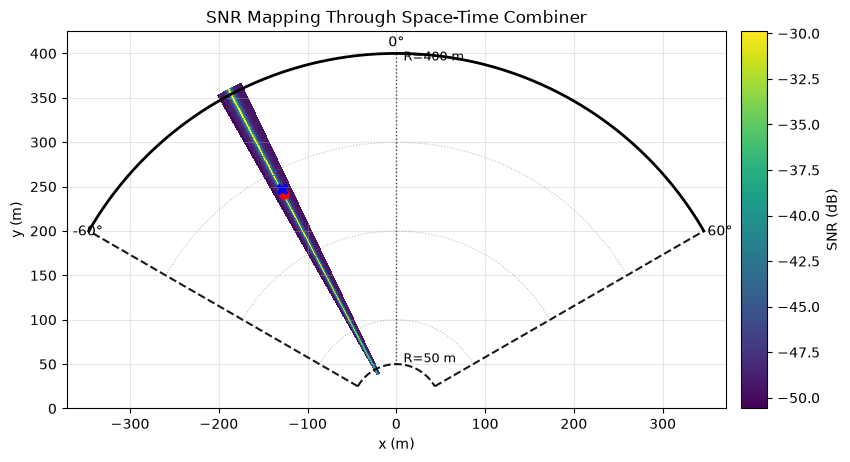

In [657]:
if 1:
    flat_max_idx = np.argmax(sample_power_map)

    # 2. Unravel the flat index into (row, col) coordinates
    row, col = np.unravel_index(flat_max_idx, sample_power_map.shape)

    fig, ax = plt.subplots(figsize=(8.6, 8.2))

    sc = ax.pcolor(
    snr_map_range * np.sin(snr_map_angle/180*np.pi), 
    snr_map_range * np.cos(snr_map_angle/180*np.pi), 
    sample_power_map,
    cmap="viridis", edgecolors="none")
    ax.scatter(
    x_true_all, y_true_all, c='r', s=42,
    )

    ax.scatter(
    range_axis[row]*np.sin(angle_axis[col]/180 *np.pi), 
    range_axis[row]*np.cos(angle_axis[col]/180 *np.pi), marker = 'x', c='b', s=42,
    lw = 3)

    draw_user_region(ax)


    xmax = R_MAX * np.sin(np.deg2rad(max(abs(THETA_MIN), abs(THETA_MAX))))
    ax.set_xlim(-xmax - 25, xmax + 25)
    ax.set_ylim(0, R_MAX + 25)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title("SNR Mapping Through Space-Time Combiner")
    ax.grid(True, alpha=0.3)
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.15)
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label("SNR (dB)")
    plt.tight_layout()
    # plt.savefig('../figures/SNRMap_STCombinner_261011.png')
    plt.show()

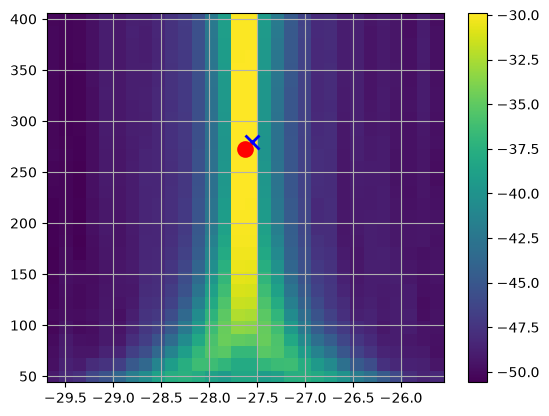

In [658]:
# Visualization of Different Maps 

plt.figure()
plt.pcolor(angle_axis, range_axis,sample_power_map)
plt.plot(angle_axis[col], range_axis[row], 'bx', ms = 10, mew = 2)
plt.plot(theta_true, R_true, 'ro', ms = 10, mew = 2)
plt.plot()
plt.grid()
plt.colorbar()
plt.show()

### Fractional Delay + Match Filtering Example

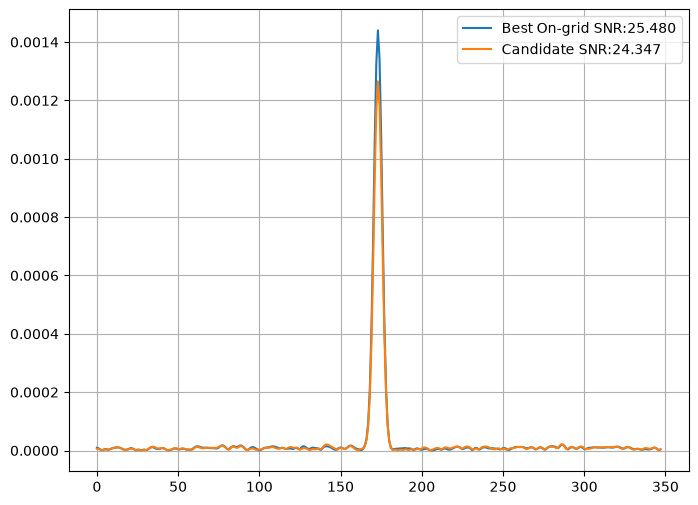

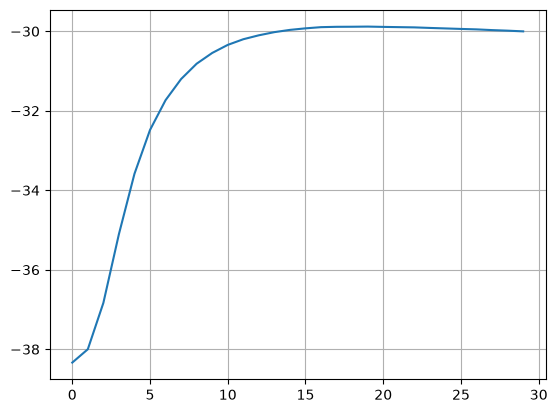

In [659]:
# Quick Verification
prop_delay_best = propagation_delays(R_true, theta_true, antenna_x=antenna_x)
prop_delay_candid = propagation_delays(range_axis[row], angle_axis[col], antenna_x=antenna_x)
Gauss_beam_best = get_GaussianBeam(prop_delay_best, K, bandwidth, dt)
Gauss_beam_candid = get_GaussianBeam(prop_delay_candid, K, bandwidth, dt)

combined_samples  = np.einsum('klm, km -> l',clean_rx_tensor + noise_rx_tensor, Gauss_beam_best.conj())
combined_samples_candid  = np.einsum('klm, km -> l',clean_rx_tensor + noise_rx_tensor, Gauss_beam_candid.conj())

best_snr          = np.linalg.norm(np.einsum('klm, km -> l',clean_rx_tensor, Gauss_beam_best.conj())) / \
                    np.linalg.norm(np.einsum('klm, km -> l',noise_rx_tensor, Gauss_beam_best.conj()))

candid_snr          = np.linalg.norm(np.einsum('klm, km -> l',clean_rx_tensor, Gauss_beam_candid.conj())) / \
                    np.linalg.norm(np.einsum('klm, km -> l',noise_rx_tensor, Gauss_beam_candid.conj()))

plt.figure(figsize = (8,6))
plt.plot(np.abs(combined_samples))
plt.plot(np.abs(combined_samples_candid))
plt.grid()
plt.legend([f"Best On-grid SNR:{20*np.log10(best_snr):.3f}", 
           f"Candidate SNR:{20*np.log10(candid_snr):.3f}"])
plt.show()

plt.Figure
plt.plot(sample_power_map[:, col])
plt.grid()
plt.show()